# Parte Comum — K-Means e métricas (Obesity)

Agrupamento com K-Means em duas passadas (k livre pelo Cotovelo e k fixo no número de classes),
mapeamento de cada cluster para a classe majoritária, matrizes de confusão e métricas.

### Escolhas de pré-processamento

| Escolha | Justificativa e implicação |
|---|---|
| Manter outliers e duplicatas | Preserva a base fornecida. Valores extremos e repetições podem influenciar os centroides. |
| Codificar binárias em 0/1 | Representa diferenças entre duas categorias sem atribuir superioridade a uma delas. |
| Codificar `CAEC` e `CALC` de 0 a 3 | Preserva a ordem de frequência (`no`, `Sometimes`, `Frequently`, `Always`). O espaçamento igual entre níveis é uma hipótese da codificação. |
| Aplicar one-hot em `MTRANS` | Representa meios de transporte sem impor uma ordem artificial entre eles. |
| Preservar os valores fracionários | Evita perda de variação e o surgimento de repetições por arredondamento. |
| Aplicar `StandardScaler` às 20 colunas de entrada | Torna as escalas comparáveis. Nas indicadoras raras, dividir pelo desvio padrão pequeno amplia a distância entre 0 e 1. |
| Excluir `NObeyesdad` do ajuste | A classe real é usada para definir o número de grupos da passada fixa e para avaliar os resultados, sem compor as distâncias do K-Means. |
| Usar PCA para visualização | Projeta os resultados em dois eixos, que explicam 25,3% da variância. O ajuste utiliza as 20 colunas codificadas e padronizadas. |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, silhouette_score
from sklearn.preprocessing import StandardScaler

ARQ_DADOS = Path('../../data/parte_comum/obesity.csv')
DIR_OUT = Path('../../out/parte_comum')
DIR_FIGURAS = DIR_OUT / 'figuras'
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

COL_CLASSE = 'NObeyesdad'
ORDEM_CLASSES = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III',
]

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def salvar(fig, nome):
    fig.savefig(DIR_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')

## 1. Carga e codificação

In [2]:
df = pd.read_csv(ARQ_DADOS)
classes = df[COL_CLASSE]
print(f'{df.shape[0]} linhas x {df.shape[1]} colunas')

2111 linhas x 17 colunas


In [3]:
COLS_BINARIAS = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']
COLS_ORDINAIS = ['CAEC', 'CALC']
COLS_NOMINAIS = ['MTRANS']

MAPA_BINARIAS = {'yes': 1, 'no': 0, 'Male': 1, 'Female': 0}
MAPA_ORDINAIS = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}

X = df.drop(columns=COL_CLASSE)

for col in COLS_BINARIAS:
    X[col] = X[col].map(MAPA_BINARIAS)

for col in COLS_ORDINAIS:
    X[col] = X[col].map(MAPA_ORDINAIS)

X = pd.get_dummies(X, columns=COLS_NOMINAIS, prefix=COLS_NOMINAIS, dtype=int)

assert X.isna().sum().sum() == 0, 'Alguma categoria ficou sem mapeamento'
print(f'{X.shape[1]} variáveis de entrada após a codificação')
X.head()

20 variáveis de entrada após a codificação


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2.0,3.0,1,0,2.0,0,0.0,1.0,0,0,0,0,1,0
1,0,21.0,1.52,56.0,1,0,3.0,3.0,1,1,3.0,1,3.0,0.0,1,0,0,0,1,0
2,1,23.0,1.80,77.0,1,0,2.0,3.0,1,0,2.0,0,2.0,1.0,2,0,0,0,1,0
3,1,27.0,1.80,87.0,0,0,3.0,3.0,1,0,2.0,0,2.0,0.0,2,0,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2.0,1.0,1,0,2.0,0,0.0,0.0,1,0,0,0,1,0


## 2. Padronização

In [4]:
scaler = StandardScaler()
X_pad = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

pd.DataFrame({
    'media_antes': X.mean(),
    'desvio_antes': X.std(),
    'media_depois': X_pad.mean(),
    'desvio_depois': X_pad.std(),
}).round(3)

,media_antes,desvio_antes,media_depois,desvio_depois
Gender,0.506,0.500,-0.0,1.0
Age,24.313,6.346,0.0,1.0
Height,1.702,0.093,-0.0,1.0
Weight,86.586,26.191,-0.0,1.0
family_history_with_overweight,0.818,0.386,-0.0,1.0
FAVC,0.884,0.320,0.0,1.0
FCVC,2.419,0.534,-0.0,1.0
NCP,2.686,0.778,0.0,1.0
CAEC,1.141,0.469,-0.0,1.0
SMOKE,0.021,0.143,-0.0,1.0


**Por que o K-Means exige padronização:**

O K-Means minimiza a soma das distâncias euclidianas quadráticas entre as observações e seus centroides. Na escala original, diferenças de dezenas de quilogramas podem dominar diferenças de frações de metro por causa das unidades. O `StandardScaler` subtrai a média e divide pelo desvio padrão em cada coluna, deixando as variáveis centradas e com variância unitária. Isso torna suas escalas comparáveis. O algoritmo pode ser executado sem esse passo, mas a escala original daria peso desproporcional a certas variáveis nesta base. [Documentação do StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

### Projeção em 2D para visualização (PCA)

In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_pad)
x_vis, y_vis = coords[:, 0], coords[:, 1]

var_explicada = pca.explained_variance_ratio_
print(f'Variância explicada: PC1 = {var_explicada[0]:.1%}, PC2 = {var_explicada[1]:.1%}, '
      f'total = {var_explicada.sum():.1%}')

Variância explicada: PC1 = 13.8%, PC2 = 11.5%, total = 25.3%


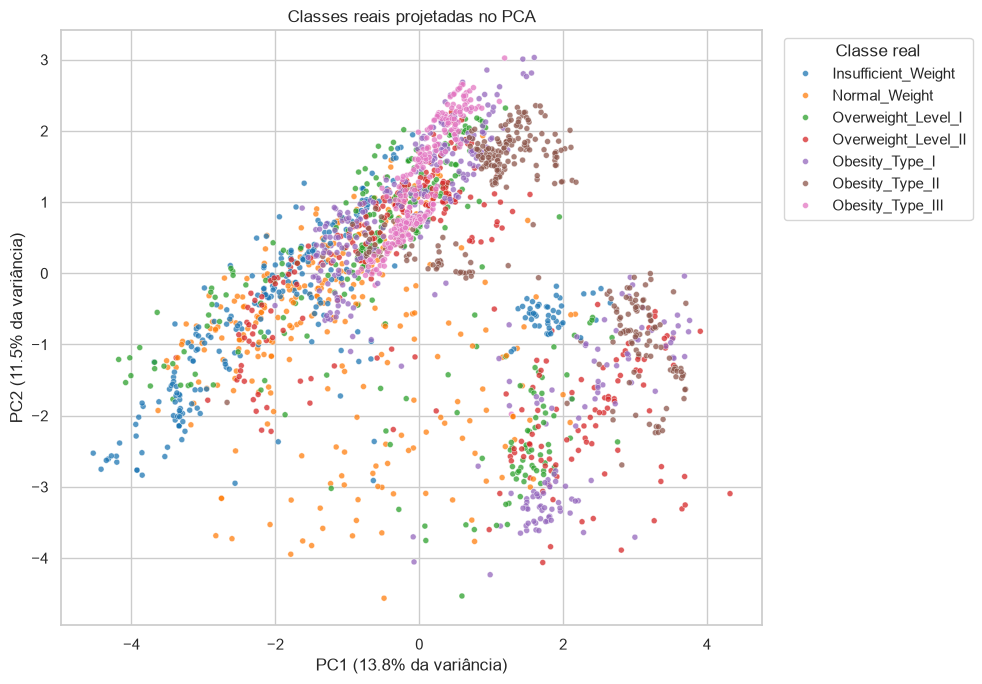

In [6]:
def plotar_pca(rotulos, titulo, nome_legenda, ordem=None, nome_arquivo=None):
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.scatterplot(x=x_vis, y=y_vis, hue=rotulos, hue_order=ordem, palette='tab10',
                    s=18, alpha=0.75, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel(f'PC1 ({var_explicada[0]:.1%} da variância)')
    ax.set_ylabel(f'PC2 ({var_explicada[1]:.1%} da variância)')
    ax.legend(title=nome_legenda, bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.tight_layout()
    if nome_arquivo:
        salvar(fig, nome_arquivo)
    plt.show()


plotar_pca(classes, 'Classes reais projetadas no PCA', 'Classe real', ORDEM_CLASSES, 'kmeans_pca_classes_reais')

## 3. Passada 1 — k livre (Método do Cotovelo)

In [7]:
KS = range(2, 11)

linhas = []
for k in KS:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    rotulos = modelo.fit_predict(X_pad)
    linhas.append({
        'k': k,
        'inercia': modelo.inertia_,
        'silhueta': silhouette_score(X_pad, rotulos, random_state=RANDOM_STATE),
    })

cotovelo = pd.DataFrame(linhas)
cotovelo.round(4)

,k,inercia,silhueta
0,2,37341.7452,0.2250
1,3,34007.5358,0.1785
2,4,31848.5189,0.1879
3,5,29833.1762,0.1925
4,6,27808.4510,0.1221
5,7,26124.9539,0.1206
6,8,25305.6230,0.1387
7,9,23045.1314,0.1653
8,10,21813.2847,0.1688


O ponto de cotovelo sugerido abaixo é calculado como o k cuja inércia normalizada fica mais distante
da reta que liga o primeiro e o último ponto da curva. A silhueta é mostrada só como apoio.

In [8]:
def k_cotovelo(ks, inercias):
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inercias, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    distancia = (1 - x_n) - y_n
    return int(x[np.argmax(distancia)])


k_sugerido = k_cotovelo(cotovelo['k'], cotovelo['inercia'])
print(f'k sugerido pelo cotovelo: {k_sugerido}')

k sugerido pelo cotovelo: 6


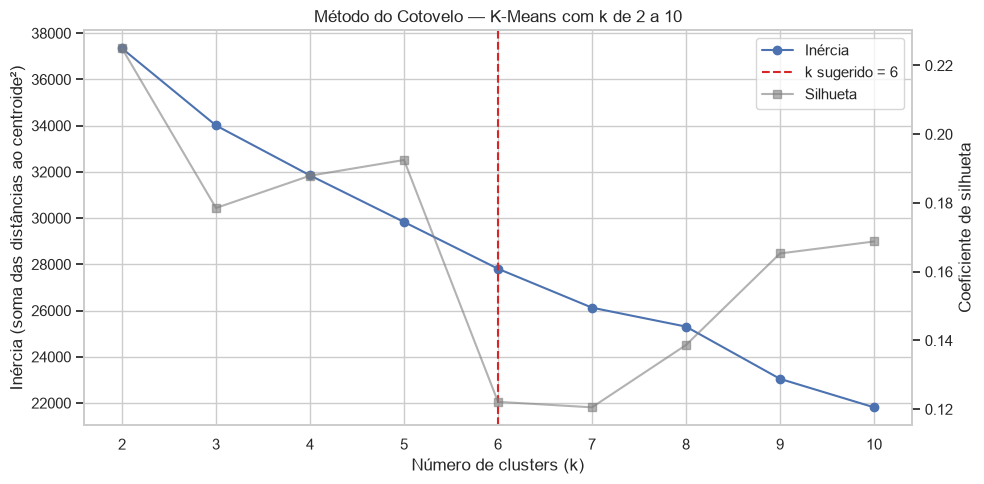

In [9]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(cotovelo['k'], cotovelo['inercia'], marker='o', label='Inércia')
ax1.axvline(k_sugerido, color='tab:red', linestyle='--', label=f'k sugerido = {k_sugerido}')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inércia (soma das distâncias ao centroide²)')
ax1.set_xticks(list(KS))

ax2 = ax1.twinx()
ax2.plot(cotovelo['k'], cotovelo['silhueta'], marker='s', color='tab:gray', alpha=0.6, label='Silhueta')
ax2.set_ylabel('Coeficiente de silhueta')
ax2.grid(False)

linhas1, rotulos1 = ax1.get_legend_handles_labels()
linhas2, rotulos2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, rotulos1 + rotulos2, loc='upper right')
ax1.set_title('Método do Cotovelo — K-Means com k de 2 a 10')
fig.tight_layout()
salvar(fig, 'kmeans_cotovelo')
plt.show()

**Escolha do k livre:**

O K-Means foi executado para valores de k entre 2 e 10. A heurística do cotovelo selecionou **k = 6** pelo maior afastamento da curva de inércia abaixo da reta que une os extremos, após normalizar os eixos. A escolha é reproduzível e independe dos rótulos reais.

O cotovelo visual é pouco acentuado. A silhueta é aproximadamente 0,122 em k = 6 e atinge o máximo do intervalo em k = 2, com 0,225. Assim, seis grupos são a escolha indicada pelo critério de inércia adotado. A silhueta oferece evidência limitada de separação nessa solução.

In [10]:
K_LIVRE = k_sugerido

kmeans_livre = KMeans(n_clusters=K_LIVRE, n_init=10, random_state=RANDOM_STATE)
cluster_livre = pd.Series(kmeans_livre.fit_predict(X_pad), index=df.index, name='cluster_livre')

cluster_livre.value_counts().sort_index().to_frame('n_registros')

,n_registros
cluster_livre,
0,505
1,445
2,56
3,692
4,7
5,406


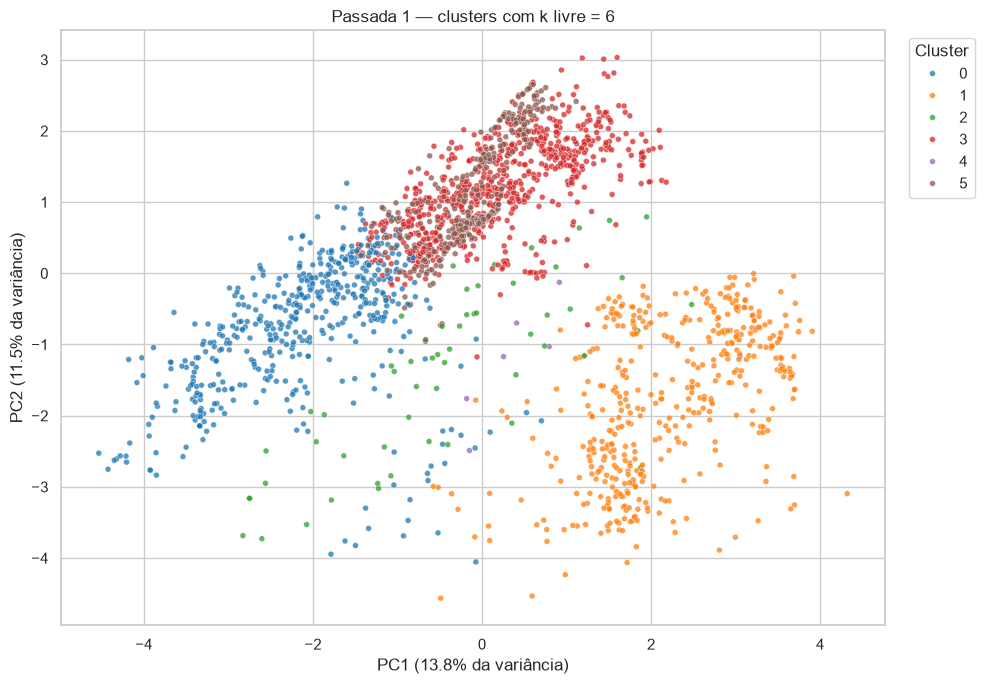

In [11]:
plotar_pca(cluster_livre.astype(str), f'Passada 1 — clusters com k livre = {K_LIVRE}', 'Cluster',
           sorted(cluster_livre.astype(str).unique(), key=int), 'kmeans_pca_livre')

## 4. Passada 2 — k fixo no número de classes

In [12]:
K_FIXO = classes.nunique()
print(f'Número de classes reais: {K_FIXO}')

kmeans_fixo = KMeans(n_clusters=K_FIXO, n_init=10, random_state=RANDOM_STATE)
cluster_fixo = pd.Series(kmeans_fixo.fit_predict(X_pad), index=df.index, name='cluster_fixo')

cluster_fixo.value_counts().sort_index().to_frame('n_registros')

Número de classes reais: 7


,n_registros
cluster_fixo,
0,439
1,381
2,43
3,793
4,437
5,7
6,11


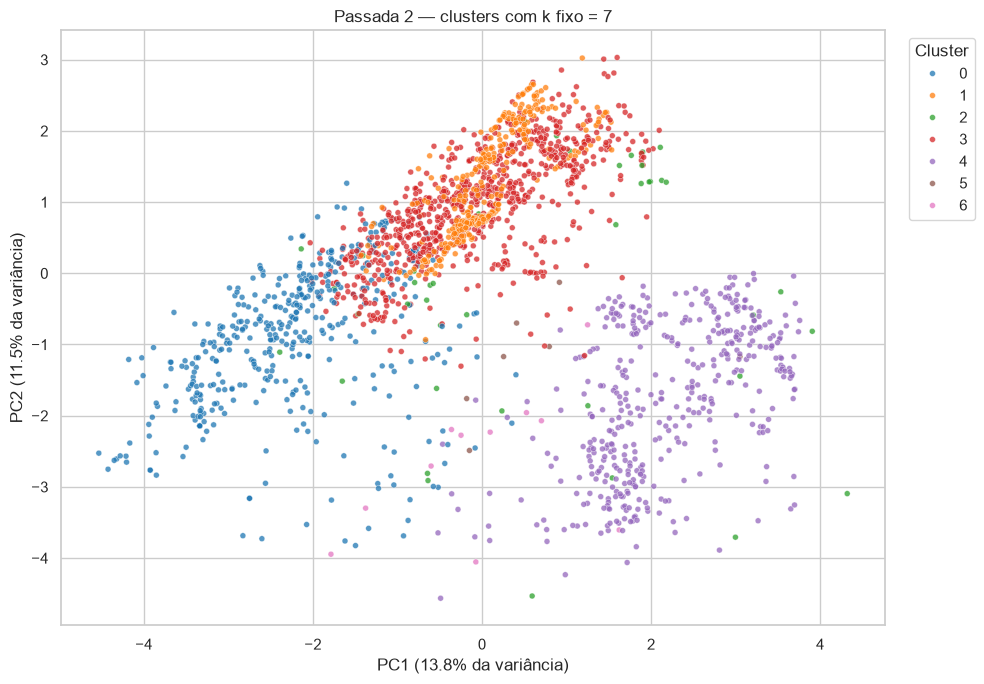

In [13]:
plotar_pca(cluster_fixo.astype(str), f'Passada 2 — clusters com k fixo = {K_FIXO}', 'Cluster',
           sorted(cluster_fixo.astype(str).unique(), key=int), 'kmeans_pca_fixo')

## 5. Mapeamento cluster → classe e matrizes de confusão

Cada cluster recebe a classe real mais frequente entre os seus registros. As duas passadas usam
as mesmas funções, para serem avaliadas exatamente do mesmo jeito.

In [14]:
def mapear_clusters(clusters, classes):
    contagem = pd.crosstab(clusters, classes)[ORDEM_CLASSES]
    mapa = contagem.idxmax(axis=1)
    return clusters.map(mapa), contagem, mapa


def matriz_confusao(reais, mapeadas, todas_as_classes=False):
    colunas = ORDEM_CLASSES if todas_as_classes else [c for c in ORDEM_CLASSES if c in set(mapeadas)]
    return pd.crosstab(reais, mapeadas).reindex(index=ORDEM_CLASSES, columns=colunas, fill_value=0)


def plotar_matriz(matriz, titulo, nome_arquivo):
    fig, ax = plt.subplots(figsize=(1.4 * matriz.shape[1] + 4, 7))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', ax=ax, cbar_kws={'label': 'Registros'})
    ax.set_title(titulo)
    ax.set_xlabel('Classe mapeada (cluster)')
    ax.set_ylabel('Classe real')
    ax.tick_params(axis='x', rotation=30)
    fig.tight_layout()
    salvar(fig, nome_arquivo)
    plt.show()


def plotar_composicao(contagem, mapa, titulo, nome_arquivo):
    tabela = contagem.T.copy()
    tabela.columns = [f'{cl}\n({mapa[cl]})' for cl in tabela.columns]
    fig, ax = plt.subplots(figsize=(1.6 * tabela.shape[1] + 4, 7))
    sns.heatmap(tabela, annot=True, fmt='d', cmap='Greens', ax=ax, cbar_kws={'label': 'Registros'})
    ax.set_title(titulo)
    ax.set_xlabel('Cluster (classe mapeada)')
    ax.set_ylabel('Classe real')
    fig.tight_layout()
    salvar(fig, nome_arquivo)
    plt.show()

### Passada 1 (k livre)

In [15]:
mapeada_livre, contagem_livre, mapa_livre = mapear_clusters(cluster_livre, classes)
contagem_livre.assign(classe_mapeada=mapa_livre)

NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_mapeada
cluster_livre,,,,,,,,
0,178,160,63,55,48,1,0,Insufficient_Weight
1,45,34,65,94,111,95,1,Obesity_Type_I
2,6,32,9,6,2,1,0,Normal_Weight
3,43,55,125,125,145,198,1,Obesity_Type_II
4,0,4,2,0,0,1,0,Normal_Weight
5,0,2,26,10,45,1,322,Obesity_Type_III


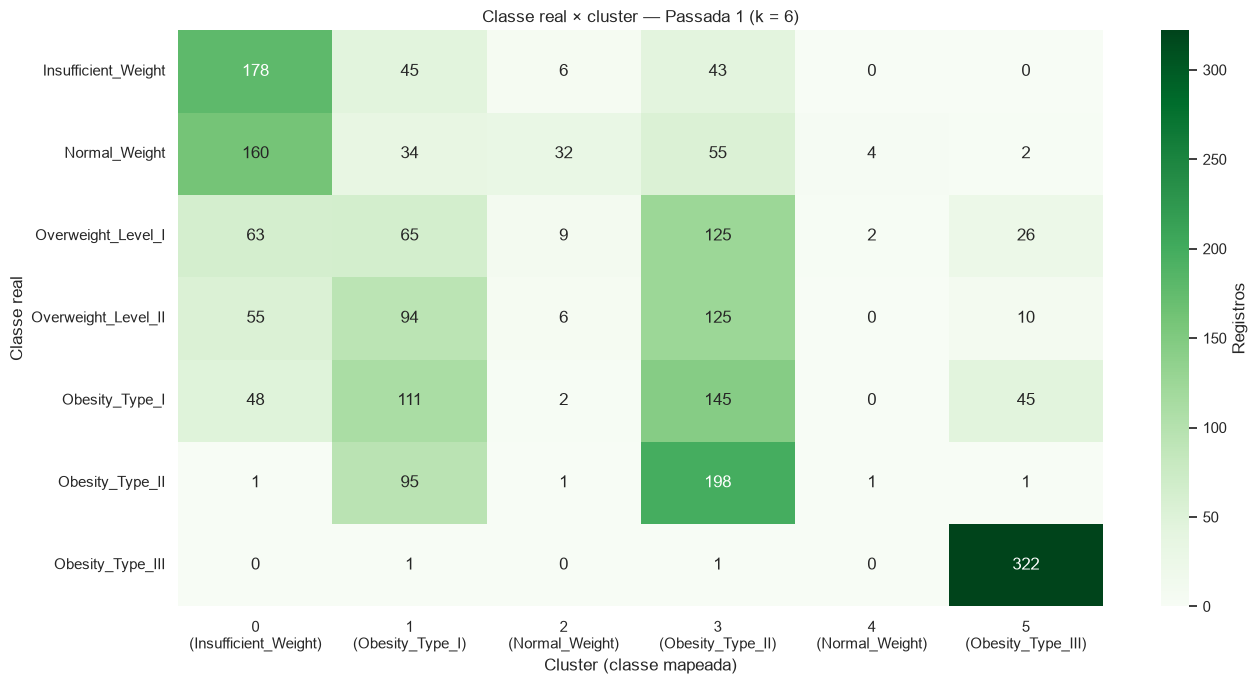

In [16]:
plotar_composicao(contagem_livre, mapa_livre, f'Classe real × cluster — Passada 1 (k = {K_LIVRE})',
                  'kmeans_composicao_livre')

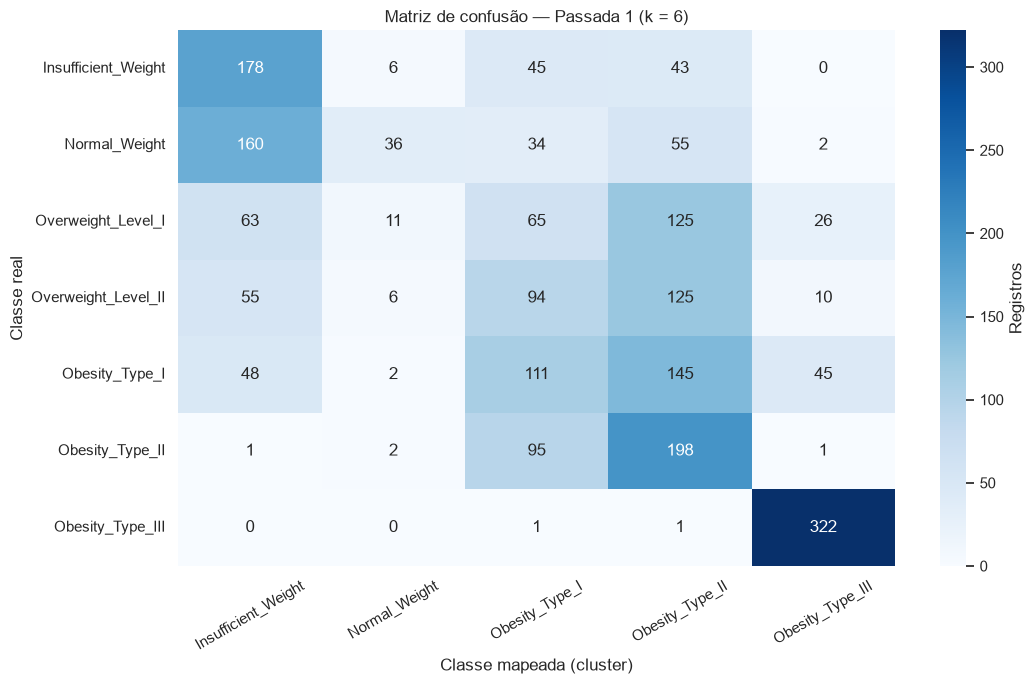

In [17]:
matriz_livre = matriz_confusao(classes, mapeada_livre)
plotar_matriz(matriz_livre, f'Matriz de confusão — Passada 1 (k = {K_LIVRE})', 'kmeans_matriz_livre')

### Passada 2 (k fixo)

In [18]:
mapeada_fixo, contagem_fixo, mapa_fixo = mapear_clusters(cluster_fixo, classes)
contagem_fixo.assign(classe_mapeada=mapa_fixo)

NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_mapeada
cluster_fixo,,,,,,,,
0,151,151,77,54,5,1,0,Insufficient_Weight
1,0,1,5,7,19,27,322,Obesity_Type_III
2,1,13,3,5,5,15,1,Obesity_Type_II
3,75,78,137,131,211,161,0,Obesity_Type_I
4,45,34,65,92,108,92,1,Obesity_Type_I
5,0,4,2,0,0,1,0,Normal_Weight
6,0,6,1,1,3,0,0,Normal_Weight


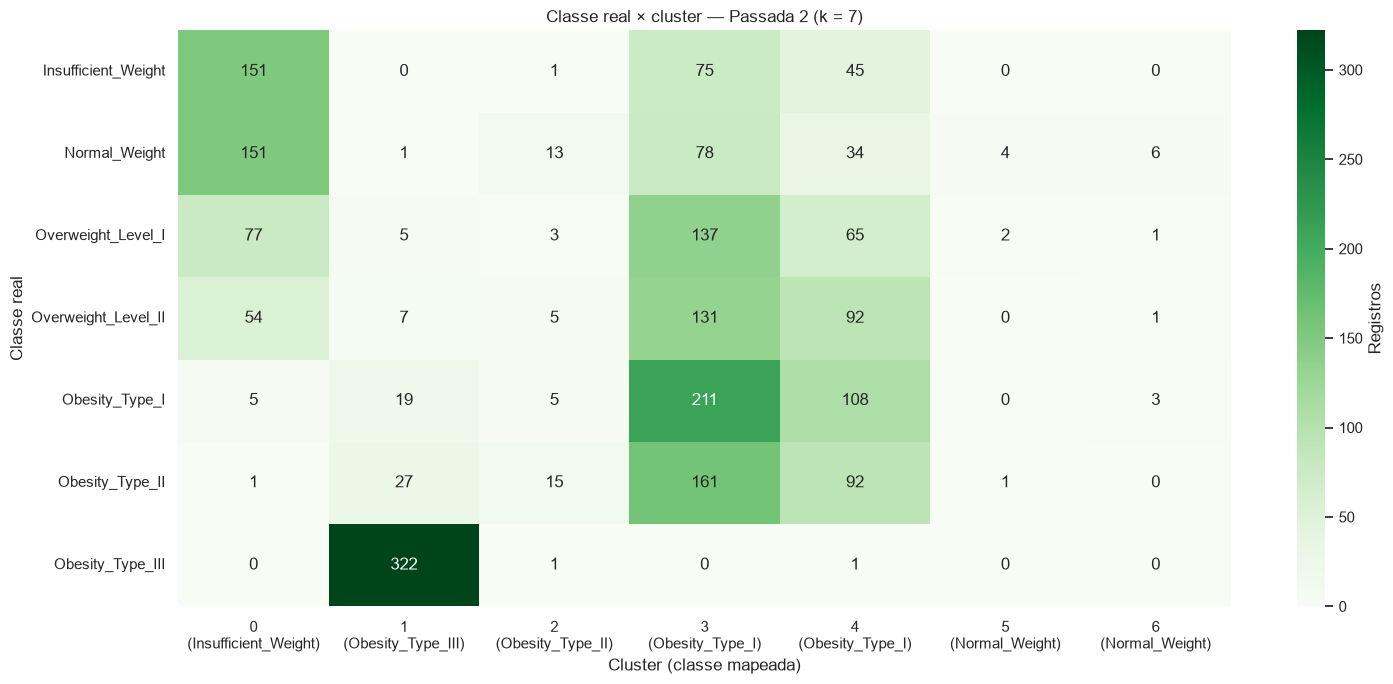

In [19]:
plotar_composicao(contagem_fixo, mapa_fixo, f'Classe real × cluster — Passada 2 (k = {K_FIXO})',
                  'kmeans_composicao_fixo')

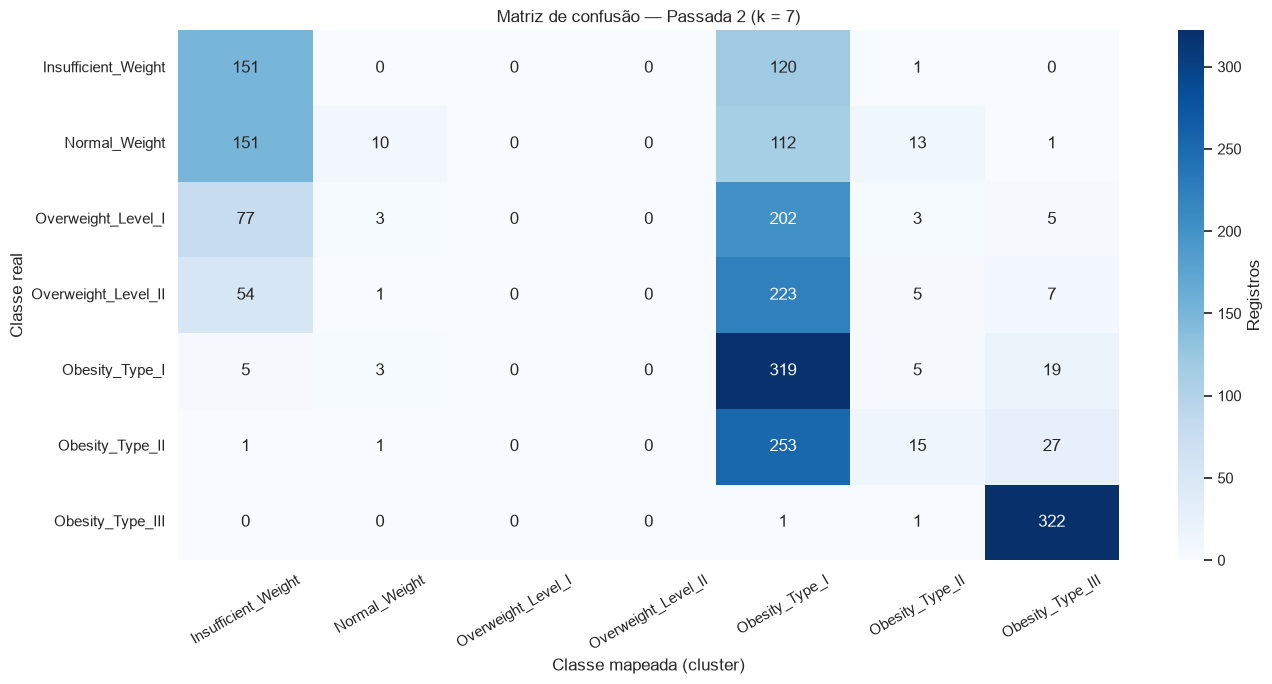

In [20]:
matriz_fixo = matriz_confusao(classes, mapeada_fixo, todas_as_classes=True)
plotar_matriz(matriz_fixo, f'Matriz de confusão — Passada 2 (k = {K_FIXO})', 'kmeans_matriz_fixo')

Na Passada 1, as classes que não são majoritárias em nenhum cluster não aparecem como coluna, por isso a
matriz pode ser retangular. Na Passada 2, a matriz inclui as 7 classes nos dois eixos; as colunas de classes
nunca atribuídas ficam zeradas. Essas classes têm recall zero e precisão indefinida (registrada como 0).

## 6. Métricas

In [21]:
def calcular_metricas(reais, mapeadas):
    acuracia = accuracy_score(reais, mapeadas)
    precisao, recall, _, suporte = precision_recall_fscore_support(
        reais, mapeadas, labels=ORDEM_CLASSES, zero_division=0
    )
    por_classe = pd.DataFrame({
        'classe': ORDEM_CLASSES,
        'precisao': precisao,
        'recall': recall,
        'suporte': suporte,
    })
    return acuracia, por_classe


acuracia_livre, metricas_livre = calcular_metricas(classes, mapeada_livre)
acuracia_fixo, metricas_fixo = calcular_metricas(classes, mapeada_fixo)

print(f'Acurácia — Passada 1 (k = {K_LIVRE}): {acuracia_livre:.3f}')
print(f'Acurácia — Passada 2 (k = {K_FIXO}): {acuracia_fixo:.3f}')

Acurácia — Passada 1 (k = 6): 0.400
Acurácia — Passada 2 (k = 7): 0.387


In [22]:
metricas_livre.round(3)

,classe,precisao,recall,suporte
0,Insufficient_Weight,0.352,0.654,272
1,Normal_Weight,0.571,0.125,287
2,Overweight_Level_I,0.000,0.000,290
3,Overweight_Level_II,0.000,0.000,290
4,Obesity_Type_I,0.249,0.316,351
5,Obesity_Type_II,0.286,0.667,297
6,Obesity_Type_III,0.793,0.994,324


In [23]:
metricas_fixo.round(3)

,classe,precisao,recall,suporte
0,Insufficient_Weight,0.344,0.555,272
1,Normal_Weight,0.556,0.035,287
2,Overweight_Level_I,0.000,0.000,290
3,Overweight_Level_II,0.000,0.000,290
4,Obesity_Type_I,0.259,0.909,351
5,Obesity_Type_II,0.349,0.051,297
6,Obesity_Type_III,0.845,0.994,324


In [24]:
for matriz, acuracia in [(matriz_livre, acuracia_livre), (matriz_fixo, acuracia_fixo)]:
    acertos = sum(matriz.loc[c, c] for c in matriz.columns)
    assert np.isclose(acertos / matriz.to_numpy().sum(), acuracia), 'Acurácia não bate com a diagonal'
print('Acurácia confere com a diagonal das duas matrizes')

Acurácia confere com a diagonal das duas matrizes


## 7. Exportação para `out/parte_comum/`

In [25]:
clusters_out = pd.DataFrame({
    'classe_real': classes,
    'x_vis': x_vis,
    'y_vis': y_vis,
    'cluster_livre': cluster_livre,
    'classe_mapeada_livre': mapeada_livre,
    'cluster_fixo': cluster_fixo,
    'classe_mapeada_fixo': mapeada_fixo,
})

resumo = pd.DataFrame({
    'passada': ['livre', 'fixo'],
    'k': [K_LIVRE, K_FIXO],
    'acuracia': [acuracia_livre, acuracia_fixo],
})

cotovelo.to_csv(DIR_OUT / 'cotovelo.csv', index=False)
clusters_out.to_csv(DIR_OUT / 'clusters.csv', index=False)
matriz_livre.to_csv(DIR_OUT / 'matriz_confusao_livre.csv')
matriz_fixo.to_csv(DIR_OUT / 'matriz_confusao_fixo.csv')
metricas_livre.to_csv(DIR_OUT / 'metricas_livre.csv', index=False)
metricas_fixo.to_csv(DIR_OUT / 'metricas_fixo.csv', index=False)
resumo.to_csv(DIR_OUT / 'resumo.csv', index=False)
contagem_livre.T.to_csv(DIR_OUT / 'composicao_livre.csv')
contagem_fixo.T.to_csv(DIR_OUT / 'composicao_fixo.csv')

sorted(p.name for p in DIR_OUT.glob('*.csv'))

['clusters.csv',
 'composicao_fixo.csv',
 'composicao_livre.csv',
 'cotovelo.csv',
 'matriz_confusao_fixo.csv',
 'matriz_confusao_livre.csv',
 'metricas_fixo.csv',
 'metricas_livre.csv',
 'resumo.csv']

## 8. Comparação das passadas

In [26]:
comparacao = metricas_livre.merge(metricas_fixo, on=['classe', 'suporte'], suffixes=('_livre', '_fixo'))
comparacao.set_index('classe').round(3)

,precisao_livre,recall_livre,suporte,precisao_fixo,recall_fixo
classe,,,,,
Insufficient_Weight,0.352,0.654,272,0.344,0.555
Normal_Weight,0.571,0.125,287,0.556,0.035
Overweight_Level_I,0.000,0.000,290,0.000,0.000
Overweight_Level_II,0.000,0.000,290,0.000,0.000
Obesity_Type_I,0.249,0.316,351,0.259,0.909
Obesity_Type_II,0.286,0.667,297,0.349,0.051
Obesity_Type_III,0.793,0.994,324,0.845,0.994


In [27]:
resumo.round(3)

,passada,k,acuracia
0,livre,6,0.400
1,fixo,7,0.387


## 9. Análise de sensibilidade — indicadoras mantidas em 0/1

Repete as duas passadas com uma representação alternativa: as indicadoras (binárias e one-hot de `MTRANS`)
ficam em 0/1 e só as demais colunas passam pelo `StandardScaler`. Os valores de k são os mesmos das passadas
principais, para que a diferença venha apenas da ponderação das variáveis.

In [28]:
COLS_INDICADORAS = COLS_BINARIAS + [c for c in X.columns if c.startswith('MTRANS_')]
COLS_ESCALONADAS = [c for c in X.columns if c not in COLS_INDICADORAS]

X_sens = X.copy().astype(float)
X_sens[COLS_ESCALONADAS] = StandardScaler().fit_transform(X[COLS_ESCALONADAS])

print('Mantidas em 0/1:', COLS_INDICADORAS)
print('Padronizadas:', COLS_ESCALONADAS)

Mantidas em 0/1: ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']
Padronizadas: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CAEC', 'CH2O', 'FAF', 'TUE', 'CALC']


In [29]:
inercias_sens = [
    KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_sens).inertia_ for k in KS
]
print(f'k sugerido pelo cotovelo nesta representação: {k_cotovelo(list(KS), inercias_sens)}')

resultados_sens = {}
for passada, k in [('livre', K_LIVRE), ('fixo', K_FIXO)]:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    clusters_sens = pd.Series(modelo.fit_predict(X_sens), index=df.index)
    mapeada_sens, contagem_sens, mapa_sens = mapear_clusters(clusters_sens, classes)
    acuracia_sens, metricas_sens = calcular_metricas(classes, mapeada_sens)
    resultados_sens[passada] = {
        'k': k,
        'clusters': clusters_sens,
        'contagem': contagem_sens,
        'mapa': mapa_sens,
        'acuracia': acuracia_sens,
        'metricas': metricas_sens,
        'silhueta': silhouette_score(X_sens, clusters_sens, random_state=RANDOM_STATE),
    }

linhas = []
for passada, cluster_principal, acuracia_principal in [
    ('livre', cluster_livre, acuracia_livre),
    ('fixo', cluster_fixo, acuracia_fixo),
]:
    r = resultados_sens[passada]
    linhas.append({
        'passada': passada, 'k': r['k'], 'representacao': 'principal',
        'acuracia': acuracia_principal,
        'silhueta': silhouette_score(X_pad, cluster_principal, random_state=RANDOM_STATE),
    })
    linhas.append({
        'passada': passada, 'k': r['k'], 'representacao': 'indicadoras_0_1',
        'acuracia': r['acuracia'], 'silhueta': r['silhueta'],
    })

resumo_sens = pd.DataFrame(linhas)
resumo_sens.round(4)

k sugerido pelo cotovelo nesta representação: 5


,passada,k,representacao,acuracia,silhueta
0,livre,6,principal,0.4003,0.1221
1,livre,6,indicadoras_0_1,0.4235,0.1358
2,fixo,7,principal,0.3870,0.1206
3,fixo,7,indicadoras_0_1,0.4557,0.1425


In [30]:
recall_sens = pd.DataFrame({
    'recall_livre_principal': metricas_livre.set_index('classe')['recall'],
    'recall_livre_0_1': resultados_sens['livre']['metricas'].set_index('classe')['recall'],
    'recall_fixo_principal': metricas_fixo.set_index('classe')['recall'],
    'recall_fixo_0_1': resultados_sens['fixo']['metricas'].set_index('classe')['recall'],
})
recall_sens.round(3)

,recall_livre_principal,recall_livre_0_1,recall_fixo_principal,recall_fixo_0_1
classe,,,,
Insufficient_Weight,0.654,0.452,0.555,0.000
Normal_Weight,0.125,0.345,0.035,0.331
Overweight_Level_I,0.000,0.276,0.000,0.548
Overweight_Level_II,0.000,0.245,0.000,0.000
Obesity_Type_I,0.316,0.000,0.909,0.513
Obesity_Type_II,0.667,0.667,0.051,0.690
Obesity_Type_III,0.994,0.997,0.994,0.997


### Meio de transporte por cluster nas duas representações

In [31]:
for passada in ['livre', 'fixo']:
    principal = cluster_livre if passada == 'livre' else cluster_fixo
    print(f'--- Passada {passada}, representação principal')
    display(pd.crosstab(principal, df['MTRANS']))
    print(f'--- Passada {passada}, indicadoras em 0/1')
    display(pd.crosstab(resultados_sens[passada]['clusters'], df['MTRANS']))

--- Passada livre, representação principal


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
cluster_livre,,,,,
0,13,0,9,483,0
1,444,0,1,0,0
2,0,0,0,0,56
3,0,0,1,691,0
4,0,7,0,0,0
5,0,0,0,406,0


--- Passada livre, indicadoras em 0/1


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
row_0,,,,,
0,219,1,2,36,2
1,24,1,4,185,14
2,59,4,1,403,19
3,10,0,2,280,9
4,15,0,1,356,1
5,130,1,1,320,11


--- Passada fixo, representação principal


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
cluster_fixo,,,,,
0,12,0,0,392,35
1,0,0,0,381,0
2,11,0,0,30,2
3,0,0,0,777,16
4,434,0,0,0,3
5,0,7,0,0,0
6,0,0,11,0,0


--- Passada fixo, indicadoras em 0/1


MTRANS,Automobile,Bike,Motorbike,Public_Transportation,Walking
row_0,,,,,
0,136,1,0,283,10
1,21,1,4,179,14
2,8,0,1,254,8
3,210,1,2,34,2
4,3,0,0,331,0
5,20,2,2,287,13
6,59,2,2,212,9


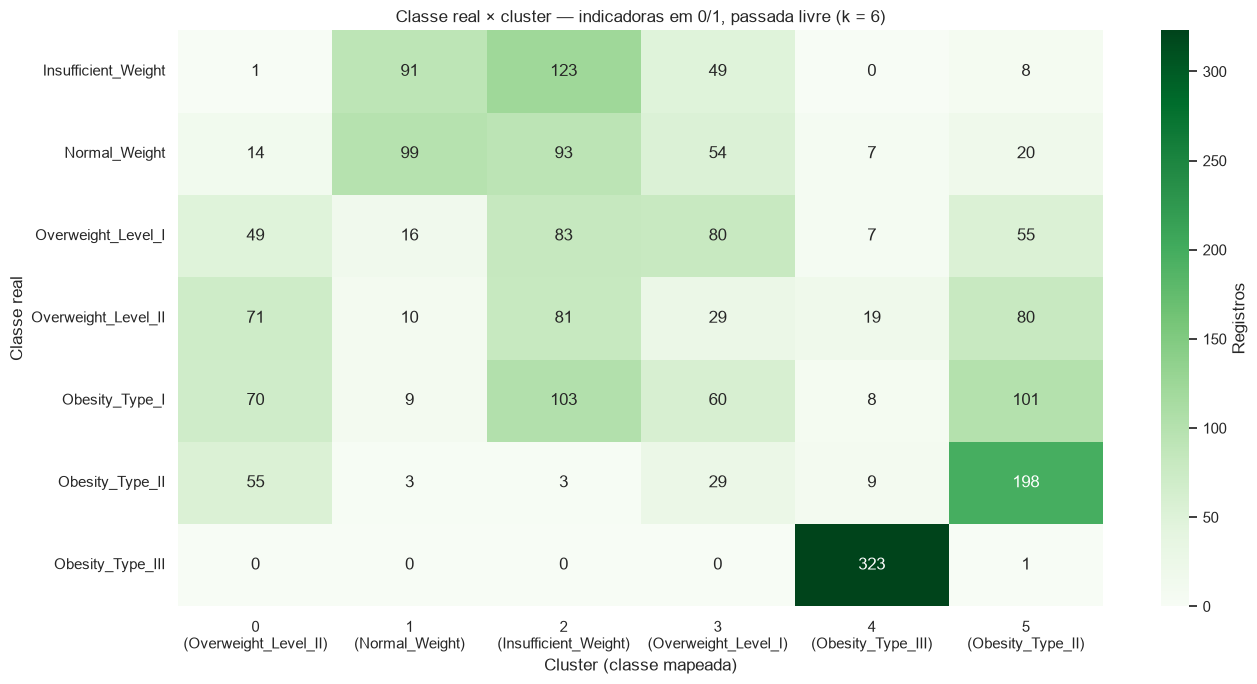

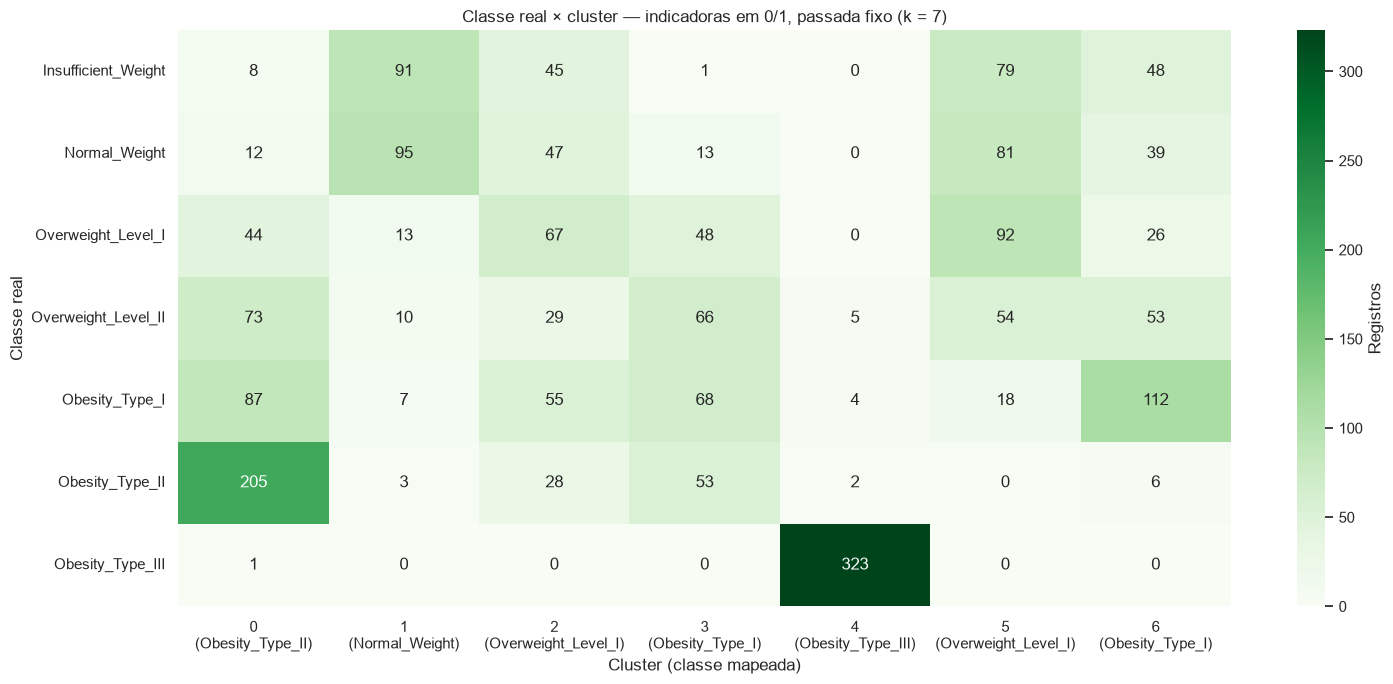

In [32]:
for passada, r in resultados_sens.items():
    plotar_composicao(r['contagem'], r['mapa'],
                      f'Classe real × cluster — indicadoras em 0/1, passada {passada} (k = {r["k"]})',
                      f'kmeans_sensibilidade_composicao_{passada}')

resumo_sens.to_csv(DIR_OUT / 'resumo_sensibilidade.csv', index=False)

**Análise do grupo:**

| k | Acurácia principal | Indicadoras 0/1 | Variação | Silhueta principal | Indicadoras 0/1 | Variação |
|---|---:|---:|---:|---:|---:|---:|
| 6 | 40,03% | 42,35% | +2,32 p.p. | 0,1221 | 0,1358 | +0,0137 |
| 7 | 38,70% | 45,57% | +6,87 p.p. | 0,1206 | 0,1425 | +0,0219 |

**A vantagem de k = 6 permanece?** Não. Na representação principal, k = 6 apresenta pequena vantagem. Com indicadoras em 0/1, k = 7 apresenta maior acurácia e silhueta. A conclusão depende da ponderação das entradas.

**Clusters exclusivos de transporte.** Na principal, há grupos exclusivos de bicicleta e caminhada com k = 6, e de bicicleta e motocicleta com k = 7. Na alternativa, essas categorias se distribuem entre os grupos. O resultado sustenta que a padronização das indicadoras raras influenciava fortemente o agrupamento. Como todas as binárias e indicadoras de transporte foram modificadas juntas, o efeito medido é conjunto.

**Recall do sobrepeso.**

| Classe | k = 6 principal | k = 6 alternativa | k = 7 principal | k = 7 alternativa |
|---|---:|---:|---:|---:|
| Sobrepeso I | 0% | 27,6% | 0% | 54,8% |
| Sobrepeso II | 0% | 24,5% | 0% | 0% |

A recuperação muda conforme a representação. Portanto, o recall zero inicial oferece evidência insuficiente para propor a fusão das classes. A alternativa também apresenta limitações e redistribui o desempenho entre categorias.

**Limite da análise.** O experimento demonstra sensibilidade à mudança avaliada. Ele não estabelece qual ponderação é ótima nem mede estabilidade entre diferentes sementes. Também não isola o efeito de cada variável e mantém os mesmos valores de k, embora o cotovelo da representação alternativa sugira cinco grupos.

### Discussão crítica

#### Comparação das passadas

| Indicador | k livre = 6 | k fixo = 7 |
|---|---:|---:|
| Acurácia após o mapeamento majoritário | 40,03% | 38,70% |
| Correspondências com os rótulos reais | 845 de 2.111 | 817 de 2.111 |
| Silhueta | 0,1221 | 0,1206 |
| Recall de obesidade tipo I | 31,6% | 90,9% |
| Recall de obesidade tipo II | 66,7% | 5,1% |
| Recall de obesidade tipo III | 99,4% | 99,4% |
| Precisão de obesidade tipo III | 79,3% | 84,5% |
| Recall de sobrepeso nível I e nível II | 0% em ambas | 0% em ambas |

Pelos indicadores avaliados, **k = 6 apresentou uma pequena vantagem nesta execução**. Foram 28 correspondências a mais, e a silhueta permaneceu baixa nas duas passadas. O ganho da passada fixa em recall para obesidade tipo I veio acompanhado de forte queda para o tipo II. A acurácia reporta concordância após o mapeamento na própria base analisada. O ajuste dos centroides ocorreu sem acesso aos rótulos.

A composição dos grupos mostra influência do transporte. Com seis clusters, há um grupo exclusivo dos sete usuários de bicicleta e outro dos 56 que caminham. Com sete clusters, há grupos exclusivos dos sete usuários de bicicleta e dos onze de motocicleta. Esse padrão é consistente com a amplificação de categorias raras pela padronização das indicadoras. A seção 9 comparou a representação principal com outra que mantém as indicadoras em 0/1. A alternativa aumentou a acurácia em 2,32 pontos percentuais com k = 6 e em 6,87 com k = 7, além de aumentar a silhueta nas duas configurações. Os clusters exclusivos das categorias raras de transporte deixaram de aparecer.

#### Granularidade das sete classes

A configuração analisada recuperou as classes de forma desigual. Os registros de obesidade tipo III se concentraram em grupos com recall de 99,4%, embora esses grupos incluam registros de outras classes. Os dois níveis de sobrepeso nunca foram majoritários em um cluster. Por isso o recall ficou em zero, mesmo com registros de sobrepeso distribuídos entre os grupos.

A tabela **classe real × cluster** permite examinar essa mistura antes do mapeamento majoritário. Na passada livre, por exemplo, um cluster contém 125 registros de cada nível de sobrepeso, 145 de obesidade tipo I e 198 de obesidade tipo II, que é a classe mais frequente naquele grupo. Essa composição mostra mistura para além dos dois níveis de sobrepeso.

Os resultados sustentam uma conclusão sobre a capacidade do K-Means de recuperar os rótulos **com a representação usada**. A análise de sensibilidade mostrou que a recuperação das classes depende da ponderação das entradas. Com k = 6, os recalls dos dois níveis de sobrepeso passaram de zero para 27,6% e 24,5%. Como foi avaliada uma alternativa de ponderação com uma única semente, permanece limitada a evidência sobre estabilidade e sobre a conveniência de unir classes. A evidência atual é insuficiente para propor a união dos níveis de sobrepeso ou sua fusão com obesidade tipo I.